<a href="https://colab.research.google.com/github/Temmy-bit/climate_project/blob/master/nootebooks/Climate_Health_Upgraded_Pipeline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Climate & Health Risk Prediction — Upgraded Pipeline

Built on top of the official starter notebook, keeping its file layout (`Train.csv`, `Test.csv`, `climate_features.csv` merged on `ID`) but changing the modeling approach in four ways:

1. **Gradient-boosted trees (LightGBM) instead of Logistic Regression** — handles nonlinearity and feature interactions the linear baseline can't, with native categorical support so nothing needs one-hot encoding.
2. **`latitude`/`longitude`/`location` are kept, not dropped.** The starter drops them because a linear model with lat/long as raw numeric inputs just learns a flat plane, and one-hot encoding `location` risks blowing up dimensionality — both are real problems for `LogisticRegression`, neither is a problem for LightGBM, which splits on these directly.
3. **5-fold stratified cross-validation instead of one train/val split** — one split can over- or under-state performance by chance; CV gives a stable read and lets every row contribute an out-of-fold prediction for honest diagnostics.
4. **No threshold tuning.** The starter's own "What's Next" section suggests "tuning the threshold used for `TargetF1`" — that directly contradicts the brief's rule that the threshold is fixed at 0.5 and tuning it is forbidden. This notebook does not do that; where probabilities need adjusting, it's through calibration during training (Section 7), which is a legitimate lever the rule doesn't block.

**Open diagnostic questions carried over from the original decomposition**, resolved empirically in Sections 3–4 rather than assumed:
- Is `is_climate_sensitive` built from the climate columns themselves, or independently? (bin-rate check)
- Which class is the minority, and by how much? (decides weighting direction)
- Does F1@0.5 track ROC-AUC, or does naive class-weighting push probabilities off-center? (the single biggest risk given the no-threshold-tuning rule)


## 0. Setup

In [ ]:
import sys, subprocess
def pip_install(pkgs):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q"] + pkgs)

pip_install(["lightgbm", "scikit-learn", "pandas", "numpy", "matplotlib", "seaborn"])


In [ ]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import f1_score, roc_auc_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.calibration import calibration_curve, CalibratedClassifierCV
import lightgbm as lgb

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
SEED = 42
np.random.seed(SEED)
pd.set_option("display.max_columns", 200)


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# ---- Config ----
DATA_DIR = "/content/drive/MyDrive/Colab Notebooks/Climate Mortality Prediction/"   # <-- EDIT: folder containing Train.csv, Test.csv, climate_features.csv

ID_COL = "ID"
TARGET = "is_climate_sensitive"
TARGET_F1 = "TargetF1"
TARGET_RAUC = "TargetRAUC"
DATE_COL = "deathdate"

OUTPUT_DIR = "/content/submissions" if os.path.isdir("/content/submissions") else "."
os.makedirs(OUTPUT_DIR, exist_ok=True)


## 1. Load and merge

In [ ]:
train = pd.read_csv(os.path.join(DATA_DIR, "Train.csv"))
test  = pd.read_csv(os.path.join(DATA_DIR, "Test.csv"))
climate_features = pd.read_csv(os.path.join(DATA_DIR, "climate_features.csv"))

print("Train shape:", train.shape)
print("Test shape:", test.shape)
print("Climate feature shape:", climate_features.shape)
print("\nClimate feature columns:", climate_features.columns.tolist())

# avoid merge collisions on any column the enrichment file re-supplies (e.g. deathdate)
overlap = [c for c in climate_features.columns if c in train.columns and c != ID_COL]
if overlap:
    print(f"\nDropping overlapping columns from climate_features before merge: {overlap}")
    climate_features = climate_features.drop(columns=overlap)

train = train.merge(climate_features, on=ID_COL, how="left")
test = test.merge(climate_features, on=ID_COL, how="left")

print("\nTrain shape after merge:", train.shape)
print("Test shape after merge:", test.shape)
train.head()


Train shape: (3146, 13)
Test shape: (1030, 12)
Climate feature shape: (4176, 18)

Climate feature columns: ['ID', 'deathdate', 'elevation', 'hot_days_30d', 'max_daily_rain_30d', 'ndvi_30d', 'ndvi_90d', 'rain_days_30d', 'rain_sum_30d', 'rain_sum_7d', 'rain_sum_90d', 'slope', 'tavg_30d', 'tavg_7d', 'tavg_90d', 'temp_range_mean_30d', 'tmax_30d', 'tmin_30d']

Dropping overlapping columns from climate_features before merge: ['deathdate']

Train shape after merge: (3146, 29)
Test shape after merge: (1030, 28)


,ID,zone,gender,deathdate,age,avg_temperature,max_temperature,min_temperature,precipitation,latitude,longitude,location,is_climate_sensitive,elevation,hot_days_30d,max_daily_rain_30d,ndvi_30d,ndvi_90d,rain_days_30d,rain_sum_30d,rain_sum_7d,rain_sum_90d,slope,tavg_30d,tavg_7d,tavg_90d,temp_range_mean_30d,tmax_30d,tmin_30d
0,ID_1FE951BD,Rural,Male,2007-10-02,30.0,21.137037,25.569017,18.451642,0.951601,0.584646,33.546344,"Izimba, Iganga, Uganda",1,1114,0,20.394434,0.72205,0.72910,18,175.264057,28.419111,421.992750,0.168545,21.425953,22.012127,21.043539,7.897970,27.608331,16.132043
1,ID_5927A443,Rural,Male,2008-01-05,2.0,24.062790,29.312026,18.977212,0.053352,0.549565,33.490326,"Nawanzu, Iganga, Uganda",1,1145,0,16.994602,0.60815,0.66985,7,71.885960,0.000000,268.439276,0.299996,22.129209,23.021381,21.992129,8.735769,29.251932,15.591455
2,ID_C4E67025,Rural,Female,2008-02-14,31.0,22.407868,26.746058,18.112977,0.090349,0.573420,33.483655,"Buluza, Iganga, Uganda",1,1145,0,15.661628,0.59290,0.61335,20,108.145379,35.970423,242.081887,0.299996,21.990516,21.557252,22.220307,7.694241,29.083597,17.420068
3,ID_44DC5CE9,Rural,Female,2008-02-15,1.0,23.315198,28.056889,18.955708,0.286814,0.549565,33.490326,"Nawanzu, Iganga, Uganda",1,1145,0,15.661628,0.59290,0.61335,19,98.524518,29.091067,229.370640,0.299996,22.032392,21.693581,22.231408,7.718027,29.083597,17.420068
4,ID_33C677BB,Rural,Female,2008-02-15,69.0,23.315198,28.056889,18.955708,0.286814,1.072343,34.226647,"Magada, Mbale City, Bugisa sub-region, Eastern...",0,1660,0,13.468142,0.53380,0.71580,13,84.030272,25.698621,186.079130,5.565486,20.143552,20.141416,20.510054,10.152887,28.300394,12.632257


In [ ]:
print("=== dtypes ===")
print(train.dtypes)
print("\n=== Missingness (train), nonzero only ===")
miss = train.isna().mean().sort_values(ascending=False)
print(miss[miss > 0])
print("\n=== Missingness (test), nonzero only ===")
miss_t = test.isna().mean().sort_values(ascending=False)
print(miss_t[miss_t > 0])


=== dtypes ===
ID                       object
zone                     object
gender                   object
deathdate                object
age                     float64
avg_temperature         float64
max_temperature         float64
min_temperature         float64
precipitation           float64
latitude                float64
longitude               float64
location                 object
is_climate_sensitive      int64
elevation                 int64
hot_days_30d              int64
max_daily_rain_30d      float64
ndvi_30d                float64
ndvi_90d                float64
rain_days_30d             int64
rain_sum_30d            float64
rain_sum_7d             float64
rain_sum_90d            float64
slope                   float64
tavg_30d                float64
tavg_7d                 float64
tavg_90d                float64
temp_range_mean_30d     float64
tmax_30d                float64
tmin_30d                float64
dtype: object

=== Missingness (train), nonzero only ===


## 2. Target distribution
Resolves which class is the minority (needed to set `scale_pos_weight` in the right direction) — this was an open assumption in the original decomposition, not something to guess at.

is_climate_sensitive
1    2047
0    1099
Name: count, dtype: int64

Positive (climate-sensitive) rate: 0.6507


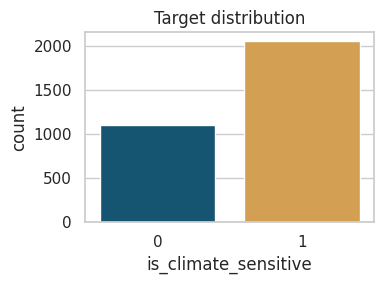

In [ ]:
print(train[TARGET].value_counts())
pos_rate = train[TARGET].mean()
print(f"\nPositive (climate-sensitive) rate: {pos_rate:.4f}")

plt.figure(figsize=(4, 3))
sns.countplot(x=TARGET, data=train, palette=["#065A82", "#E8A33D"])
plt.title("Target distribution")
plt.tight_layout()
plt.show()


## 3. Does the label trace back to the climate columns themselves?
Bin each raw climate column and check the label-positive rate per bin. A flat rate means climate is indirect signal; a sharp monotonic jump means the label is close to climate-threshold-defined — which changes how much weight to put on these columns versus the demographic/spatial ones.

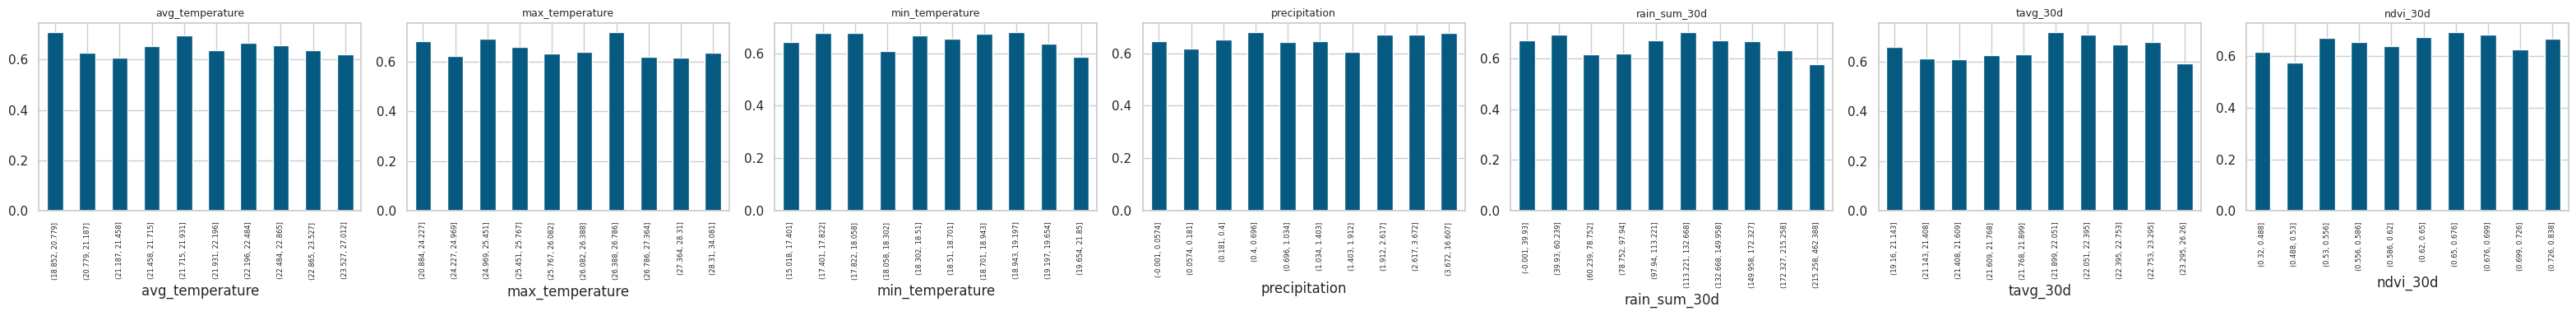

avg_temperature: bin-rate spread = 0.102
max_temperature: bin-rate spread = 0.102
min_temperature: bin-rate spread = 0.092
precipitation: bin-rate spread = 0.074
rain_sum_30d: bin-rate spread = 0.127
tavg_30d: bin-rate spread = 0.125
ndvi_30d: bin-rate spread = 0.118


In [ ]:
climate_candidates = [c for c in ["avg_temperature", "max_temperature", "min_temperature", "precipitation"] if c in train.columns]
# also probe a couple of enrichment columns if present
climate_candidates += [c for c in ["rain_sum_30d", "tavg_30d", "ndvi_30d"] if c in train.columns]

n = len(climate_candidates)
fig, axes = plt.subplots(1, n, figsize=(4.5 * n, 4))
if n == 1:
    axes = [axes]

bin_spreads = {}
for ax, col in zip(axes, climate_candidates):
    valid = train[[col, TARGET]].dropna()
    binned = pd.qcut(valid[col], q=10, duplicates="drop")
    rate_by_bin = valid.groupby(binned, observed=True)[TARGET].mean()
    bin_spreads[col] = rate_by_bin.max() - rate_by_bin.min()
    rate_by_bin.plot(kind="bar", ax=ax, color="#065A82")
    ax.set_title(col, fontsize=9)
    ax.tick_params(axis="x", rotation=90, labelsize=6)

plt.tight_layout()
plt.show()

for col, spread in bin_spreads.items():
    print(f"{col}: bin-rate spread = {spread:.3f}")


**Read this before trusting feature importance in Section 8.** A large spread (bottom bin near 0, top bin near 1) on `avg_temperature` or `precipitation` means the model will lean heavily on these almost by construction — that's expected, not a discovery, and worth stating plainly rather than presenting as insight. A flat spread means climate columns are one signal among several, and demographic/spatial features in Section 5 likely carry comparable weight.

## 4. Feature engineering

In [ ]:
def engineer_features(df):
    df = df.copy()
    df[DATE_COL] = pd.to_datetime(df[DATE_COL], errors="coerce")
    df["day_of_year"] = df[DATE_COL].dt.dayofyear
    df["death_month"] = df[DATE_COL].dt.month
    df["season_sin"] = np.sin(2 * np.pi * df["day_of_year"] / 365.25)
    df["season_cos"] = np.cos(2 * np.pi * df["day_of_year"] / 365.25)

    if "max_temperature" in df.columns and "min_temperature" in df.columns:
        df["temperature_range"] = df["max_temperature"] - df["min_temperature"]
    if "precipitation" in df.columns:
        df["is_rainy_day"] = (df["precipitation"] > 0).astype(int)

    df = df.drop(columns=[DATE_COL])
    return df

train_df = engineer_features(train)
test_df = engineer_features(test)

# categorical vs numeric -- LightGBM handles categoricals natively, so nothing is one-hot encoded
# and location/zone/latitude/longitude are KEPT, unlike the starter notebook.
drop_cols = [TARGET, ID_COL]
X = train_df.drop(columns=drop_cols)
y = train_df[TARGET]
X_test = test_df.drop(columns=[ID_COL])

categorical_features = [c for c in X.columns if X[c].dtype == "object"]
numeric_features = [c for c in X.columns if c not in categorical_features]

for col in categorical_features:
    X[col] = X[col].astype("category")
    X_test[col] = X_test[col].astype("category")
    # align category sets so LightGBM sees the same codes in train/test
    all_cats = pd.concat([X[col], X_test[col]]).astype("category").cat.categories
    X[col] = X[col].cat.set_categories(all_cats)
    X_test[col] = X_test[col].cat.set_categories(all_cats)

print("Categorical features (kept natively, not one-hot encoded):", categorical_features)
print("Numeric features:", numeric_features)
X.head()


Categorical features (kept natively, not one-hot encoded): ['zone', 'gender', 'location']
Numeric features: ['age', 'avg_temperature', 'max_temperature', 'min_temperature', 'precipitation', 'latitude', 'longitude', 'elevation', 'hot_days_30d', 'max_daily_rain_30d', 'ndvi_30d', 'ndvi_90d', 'rain_days_30d', 'rain_sum_30d', 'rain_sum_7d', 'rain_sum_90d', 'slope', 'tavg_30d', 'tavg_7d', 'tavg_90d', 'temp_range_mean_30d', 'tmax_30d', 'tmin_30d', 'day_of_year', 'death_month', 'season_sin', 'season_cos', 'temperature_range', 'is_rainy_day']


,zone,gender,age,avg_temperature,max_temperature,min_temperature,precipitation,latitude,longitude,location,elevation,hot_days_30d,max_daily_rain_30d,ndvi_30d,ndvi_90d,rain_days_30d,rain_sum_30d,rain_sum_7d,rain_sum_90d,slope,tavg_30d,tavg_7d,tavg_90d,temp_range_mean_30d,tmax_30d,tmin_30d,day_of_year,death_month,season_sin,season_cos,temperature_range,is_rainy_day
0,Rural,Male,30.0,21.137037,25.569017,18.451642,0.951601,0.584646,33.546344,"Izimba, Iganga, Uganda",1114,0,20.394434,0.72205,0.72910,18,175.264057,28.419111,421.992750,0.168545,21.425953,22.012127,21.043539,7.897970,27.608331,16.132043,275,10,-0.999833,0.018277,7.117375,1
1,Rural,Male,2.0,24.062790,29.312026,18.977212,0.053352,0.549565,33.490326,"Nawanzu, Iganga, Uganda",1145,0,16.994602,0.60815,0.66985,7,71.885960,0.000000,268.439276,0.299996,22.129209,23.021381,21.992129,8.735769,29.251932,15.591455,5,1,0.085906,0.996303,10.334814,1
2,Rural,Female,31.0,22.407868,26.746058,18.112977,0.090349,0.573420,33.483655,"Buluza, Iganga, Uganda",1145,0,15.661628,0.59290,0.61335,20,108.145379,35.970423,242.081887,0.299996,21.990516,21.557252,22.220307,7.694241,29.083597,17.420068,45,2,0.699079,0.715044,8.633080,1
3,Rural,Female,1.0,23.315198,28.056889,18.955708,0.286814,0.549565,33.490326,"Nawanzu, Iganga, Uganda",1145,0,15.661628,0.59290,0.61335,19,98.524518,29.091067,229.370640,0.299996,22.032392,21.693581,22.231408,7.718027,29.083597,17.420068,46,2,0.711276,0.702913,9.101181,1
4,Rural,Female,69.0,23.315198,28.056889,18.955708,0.286814,1.072343,34.226647,"Magada, Mbale City, Bugisa sub-region, Eastern...",1660,0,13.468142,0.53380,0.71580,13,84.030272,25.698621,186.079130,5.565486,20.143552,20.141416,20.510054,10.152887,28.300394,12.632257,46,2,0.711276,0.702913,9.101181,1


## 5. Cross-validated baseline — F1@0.5 vs. ROC-AUC
This is the test that resolves the biggest open risk: whether class-weighting for imbalance pushes probabilities away from a usable 0.5 cutoff. Read the gap between F1@0.5 and AUC below before trusting the final submission.

In [ ]:
scale_pos_weight = (1 - pos_rate) / pos_rate
print(f"scale_pos_weight = {scale_pos_weight:.3f} (direction set from Section 2's measured positive rate)")

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
oof_proba = np.zeros(len(X))
fold_metrics = []

lgb_params = dict(
    objective="binary",
    n_estimators=600,
    learning_rate=0.04,
    num_leaves=31,
    min_child_samples=20,
    scale_pos_weight=scale_pos_weight,
    random_state=SEED,
    verbose=-1,
)

for fold, (tr_idx, val_idx) in enumerate(skf.split(X, y)):
    model = lgb.LGBMClassifier(**lgb_params)
    model.fit(
        X.iloc[tr_idx], y.iloc[tr_idx],
        eval_set=[(X.iloc[val_idx], y.iloc[val_idx])],
        categorical_feature=categorical_features,
        callbacks=[lgb.early_stopping(40, verbose=False)],
    )
    proba = model.predict_proba(X.iloc[val_idx])[:, 1]
    oof_proba[val_idx] = proba

    pred = (proba >= 0.5).astype(int)
    f1 = f1_score(y.iloc[val_idx], pred)
    auc = roc_auc_score(y.iloc[val_idx], proba)
    fold_metrics.append({"fold": fold, "f1_at_0.5": f1, "auc": auc})
    print(f"Fold {fold}: F1@0.5={f1:.4f}  AUC={auc:.4f}")

fold_df = pd.DataFrame(fold_metrics)
oof_pred = (oof_proba >= 0.5).astype(int)
overall_f1 = f1_score(y, oof_pred)
overall_auc = roc_auc_score(y, oof_proba)
overall_merged = 0.6 * overall_f1 + 0.4 * overall_auc

print(f"\nMean fold F1@0.5: {fold_df['f1_at_0.5'].mean():.4f}")
print(f"Mean fold AUC: {fold_df['auc'].mean():.4f}")
print(f"\nOOF pooled F1@0.5: {overall_f1:.4f}")
print(f"OOF pooled AUC: {overall_auc:.4f}")
print(f"OOF merged score (0.6xF1 + 0.4xAUC): {overall_merged:.4f}")

print("\nClassification report (OOF):")
print(classification_report(y, oof_pred, digits=3))


scale_pos_weight = 0.537 (direction set from Section 2's measured positive rate)
Fold 0: F1@0.5=0.8147  AUC=0.7937
Fold 1: F1@0.5=0.7834  AUC=0.7972
Fold 2: F1@0.5=0.7876  AUC=0.7766
Fold 3: F1@0.5=0.7673  AUC=0.7789
Fold 4: F1@0.5=0.7769  AUC=0.7801

Mean fold F1@0.5: 0.7860
Mean fold AUC: 0.7853

OOF pooled F1@0.5: 0.7862
OOF pooled AUC: 0.7845
OOF merged score (0.6xF1 + 0.4xAUC): 0.7855

Classification report (OOF):
              precision    recall  f1-score   support

           0      0.603     0.695     0.646      1099
           1      0.822     0.754     0.786      2047

    accuracy                          0.733      3146
   macro avg      0.712     0.724     0.716      3146
weighted avg      0.745     0.733     0.737      3146



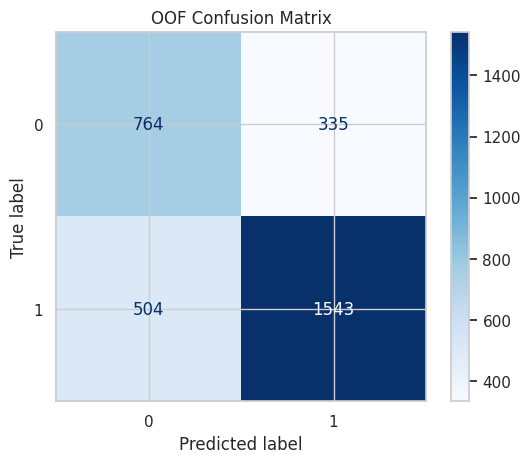

In [ ]:
cm = confusion_matrix(y, oof_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0, 1])
disp.plot(cmap="Blues")
plt.title("OOF Confusion Matrix")
plt.show()


**Compare this to the starter notebook's LogisticRegression numbers before concluding anything** — if you've already run the starter, put its single-split F1/AUC/Final Score side by side with the OOF numbers above. A higher OOF merged score here confirms the tree-based approach is a real improvement, not just a different-looking pipeline. If F1@0.5 lags AUC by a wide margin, go straight to Section 7 (calibration) before trusting Section 9's submission.

## 6. Calibration check
Checks whether predicted probabilities are trustworthy right at the fixed 0.5 cutoff — the one lever still available given the brief's "no threshold tuning" rule is to fix *calibration during training*, never to search for a better cutoff after the fact.

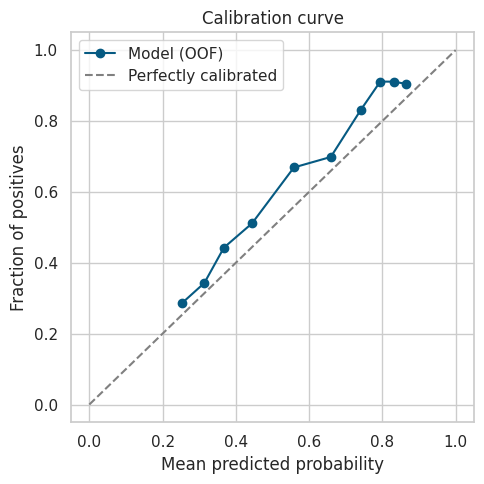

In [ ]:
prob_true, prob_pred = calibration_curve(y, oof_proba, n_bins=10, strategy="quantile")

plt.figure(figsize=(5, 5))
plt.plot(prob_pred, prob_true, marker="o", label="Model (OOF)", color="#065A82")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Perfectly calibrated")
plt.xlabel("Mean predicted probability")
plt.ylabel("Fraction of positives")
plt.title("Calibration curve")
plt.legend()
plt.tight_layout()
plt.show()


## 7. Final model — optionally calibrated, trained on full data

In [ ]:
USE_CALIBRATION = True  # <-- set True if Section 6's curve sits well off the diagonal near p=0.5

if USE_CALIBRATION:
    base_model = lgb.LGBMClassifier(**lgb_params)
    final_model = CalibratedClassifierCV(base_model, method="isotonic", cv=5)
    final_model.fit(X, y)
else:
    final_model = lgb.LGBMClassifier(**lgb_params)
    final_model.fit(X, y, categorical_feature=categorical_features)

print("Final model trained.", "(calibrated)" if USE_CALIBRATION else "(uncalibrated)")


Final model trained. (calibrated)


## 8. Feature importance

In [ ]:
if not USE_CALIBRATION:
    importance_df = pd.DataFrame({
        "feature": X.columns,
        "importance": final_model.feature_importances_,
    }).sort_values("importance", ascending=False)

    plt.figure(figsize=(8, 7))
    plt.barh(importance_df["feature"].head(20)[::-1], importance_df["importance"].head(20)[::-1], color="#065A82")
    plt.title("Top 20 feature importances (gain-based)")
    plt.tight_layout()
    plt.show()
    display(importance_df.head(20))
else:
    print("Skipping native feature importance plot -- CalibratedClassifierCV wraps the base model.")
    print("Re-run with USE_CALIBRATION=False temporarily if you need to inspect importances.")


Skipping native feature importance plot -- CalibratedClassifierCV wraps the base model.
Re-run with USE_CALIBRATION=False temporarily if you need to inspect importances.


Cross-check the top features against Section 3's bin-spread numbers. If `avg_temperature`/`precipitation` (or their enrichment-file cousins like `tavg_30d`) dominate *and* showed large spread in Section 3, that's internally consistent evidence the label leans on climate thresholds directly — say so plainly in any write-up rather than treating it as a novel finding.

## 9. Predict on Test.csv and write submission.csv
Format: `ID, TargetF1, TargetRAUC` — both columns come from the same model's probability output, per the brief's requirement; `TargetF1` is that probability at the fixed 0.5 cutoff, never a tuned threshold.

In [ ]:
test_proba = final_model.predict_proba(X_test)[:, 1]
test_pred = (test_proba >= 0.5).astype(int)

submission = pd.DataFrame({
    ID_COL: test[ID_COL],
    TARGET_F1: test_pred,
    TARGET_RAUC: test_proba,
})

assert len(submission) == len(test), "Row count mismatch"
assert submission[TARGET_F1].isin([0, 1]).all(), "TargetF1 must be binary"
assert submission[TARGET_RAUC].between(0, 1).all(), "TargetRAUC must be a valid probability"
assert submission[ID_COL].isna().sum() == 0, "Missing IDs"

submission_path = os.path.join(OUTPUT_DIR, "submission_2.csv")
submission.to_csv(submission_path, index=False)
print(f"submission.csv written to {submission_path} with {len(submission)} rows.")
print(f"Predicted positive rate (test): {test_pred.mean():.4f}  (train was {pos_rate:.4f})")
submission.head(10)


submission.csv written to ./submission_2.csv with 1030 rows.
Predicted positive rate (test): 0.8631  (train was 0.6507)


,ID,TargetF1,TargetRAUC
0,ID_E760D84B,0,0.493108
1,ID_6EDEA907,1,0.742355
2,ID_B9FFC8D8,1,0.536662
3,ID_74C6C94E,1,0.619423
4,ID_0E02825D,1,0.683523
5,ID_DA1C6468,1,0.754875
6,ID_82EBD610,1,0.581262
7,ID_791C412A,1,0.784631
8,ID_8FB9365C,1,0.675980
9,ID_724491A7,1,0.553514


**Sanity check** the printed test positive rate against train's. A large divergence usually means either genuine train/test distribution shift, or a calibration issue worth revisiting in Section 6 before trusting this file.

## 10. Summary

| Check | Result |
|---|---|
| Train positive rate | *(Section 2)* |
| Climate-column bin-rate spread | *(Section 3)* |
| OOF F1@0.5 | *(Section 5)* |
| OOF AUC | *(Section 5)* |
| OOF merged score (0.6×F1 + 0.4×AUC) | *(Section 5)* |
| Calibration used | *(Section 7 flag)* |
| vs. starter LogisticRegression baseline | *(fill in once both are run side by side)* |

*Note which of the diagnostic questions were resolved and in which direction — that's the real finding, more than the headline score.*
